sklearn datasets:
```python
import sklearn.datasets


# TL;DR


load sklearn datasets

```python
from sklearn import datasets 
newsgroups = datasets.fetch_20newsgroups_vectorized()
wine = datasets.load_wine()
X, y = newsgroups.data, newsgroups.target
X, y = wine.data, wine.target



Support Vector Machine

```python
from sklearn.svm import LinearSVC, SVC

Decision boundary: different classification boundaries

```python
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

lr = LogisticRegression().fit(X,y)

DecisionBoundaryDisplay.from_estimator( # chart with boundaries: each class boudnary a color
    lr,
    X,
    response_method="predict",
    cmap=plt.cm.coolwarm,
)
plt.scatter(X[:,0], X[:,1], c = y, cmap=plt.cm.coolwarm) # plot values
```

dot operation: for X * coeff + intercept

```python
x = np.arange(3)
y = np.arange(3,6)
x@y == np.sum(x*y) # dot product here

# 1: Applying logistic regression and SVM
```python

# KNN
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 1)

# Train Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y)

# Applying KNN & train test splt
knn.fit(X_train,y_train)
y_pred = knn.predict(X_test)
score = knn.score(X_test,y_test)



Applying logistic regression and SVM

```python
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train, y_train)
lr.predict(X_test)
lr.score(X_test, y_test)
```



Loading wine data:
```python
import sklearn.datasets
wine = sklearn.datasets.load_wine()
```



Using LinearSVC (more on that later)
```python
from sklearn.svm import LinearSVC
svm = LinarSVC()
svm.fit(X_train, y_train)
svm.score(X_test, y_test)
```


Underfitting: 
- model is too simple; low training accuracy  
(lr.score(X_train, y_train) low)

Overfitting: 
- Model is too complex; low test accuracy  
(lr.score(X_test, y_test) low)

Let's practice!

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn import datasets 
from sklearn.model_selection import train_test_split

digits = datasets.load_digits()
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target)

# Logistic regression
lr = LogisticRegression( max_iter = 10000000)
lr.fit(X_train, y_train)

# SVM
svm = LinearSVC(max_iter = 10000000)
svm.fit(X_train, y_train)

print('accuracy:')
for model in ['lr', 'svm']:
    print(model, 'train data', globals()[model].score(X_train, y_train))
    print(model, 'test data', globals()[model].score(X_test, y_test))


accuracy:
lr train data 1.0
lr test data 0.9644444444444444
svm train data 0.9970304380103935
svm test data 0.9511111111111111


Support Vector Machine, from Bing:

Sure! Support Vector Machines (SVM) is a type of machine learning algorithm that can be used for classification and regression analysis. The goal of SVM is to find the hyperplane that maximizes the margin between the two classes. The margin is defined as the distance between the hyperplane and the closest data points from each class. The hyperplane that maximizes the margin is called the maximum margin hyperplane.

SVMs can be used for both linear and nonlinear classification and regression problems. SVMs are particularly useful when there are many features in the dataset, as they can handle high-dimensional data well.

Sure! Let’s say we have a dataset of two classes of points: red and blue. We want to find a hyperplane that separates the two classes. In two-dimensional space, the hyperplane is a line. The goal of Support Vector Machines (SVM) is to find the line that maximizes the margin between the two classes. The margin is defined as the distance between the line and the closest data points from each class. The hyperplane that maximizes the margin is called the maximum margin hyperplane.

Here’s an example of a hyperplane that separates two classes of points:

Hyperplane example

In this example, the red and blue points represent two different classes. The hyperplane is the line that separates the two classes. The margin is defined as the distance between the line and the closest data points from each class.

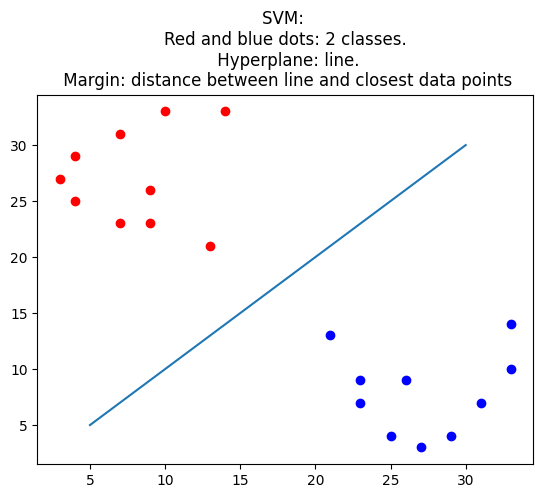

In [15]:
# not from datacamp: Me replicating answer from Bing
import matplotlib.pyplot as plt 
import numpy as np 
x1 = y2 = np.random.randint(2,15,10)
y1 = x2 = np.random.randint(20,35,10)

plt.scatter(x1, y1, c = 'red')
plt.scatter(x2, y2, c = 'blue')
plt.plot([5,30], [5,30])
plt.title('SVM: \nRed and blue dots: 2 classes.\n Hyperplane: line.\n Margin: distance between line and closest data points')
plt.show()

Linear decision boundaries: Vocabulary
- Classification
- Decision boundary
- Linear classifier (ex: Logistic Regression, linear SVM)
- Linearly separable: data set explainable by a linear classifier

Let's practice!

In [51]:
from sklearn import datasets
from sklearn.linear_model import LogisticRegression 
from sklearn.svm import SVC, LinearSVC 
from sklearn.neighbors import KNeighborsClassifier 

wine = datasets.load_wine()
X,y = wine['data'][:128,:2], wine['target'][:128]

classifiers = [LogisticRegression(), LinearSVC(), SVC(), KNeighborsClassifier()]

for c in classifiers:
    c.fit(X,y)

classifiers[1].score(X,y)

f:\git\env\Lib\site-packages\sklearn\svm\_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


0.8984375

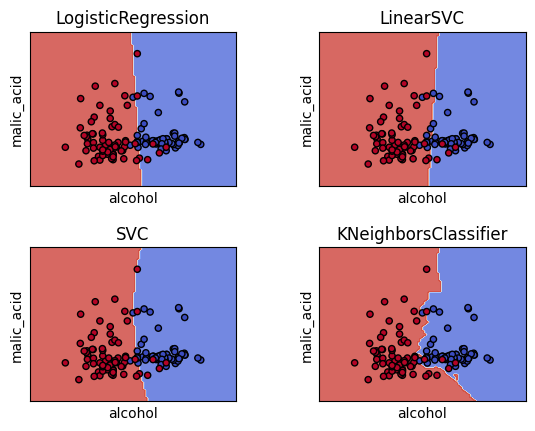

In [66]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
# Set-up 2x2 grid for plotting.
fig, sub = plt.subplots(2, 2)
plt.subplots_adjust(wspace=0.4, hspace=0.4)

X0, X1 = X[:, 0], X[:, 1]

for clf, ax in zip(classifiers, sub.flatten()):
    disp = DecisionBoundaryDisplay.from_estimator(
        clf,
        X,
        response_method="predict",
        cmap=plt.cm.coolwarm,
        alpha=0.8,
        ax=ax,
        xlabel=wine.feature_names[0],
        ylabel=wine.feature_names[1],
    )
    ax.scatter(X0, X1, c=y, cmap=plt.cm.coolwarm, s=20, edgecolors="k")
    ax.set_xticks(())
    ax.set_yticks(())
    ax.set_title(str(clf.__class__).split('.')[-1][:-2])

plt.show()

# 2: Loss functions

Linear classifiers: Prediction equations

Dot products
```python
x = np.arange(3)
y = np.arange(3,6)
x@y == np.sum(x*y) # dot product here

Linear classifier prediction
- raw model output = coefficients * features + intercept
- Linear classifier prediction: compute raw model output, check sign
    - positive: one class
    - negative: other class
- same for logistic regression and linear SVM

```python
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X,y)
lr.predict(X)[10] # 0
lr.predict(x)[20] # 1
lr.coef_ @ x[10] + lr.intercept_ # raw model output = -33 = class 0
lr.coef_ @ x[20] + lr.intercept_ # raw model output = 0.8 = class 1
```


Let's practice!

array([[-3, -1]])

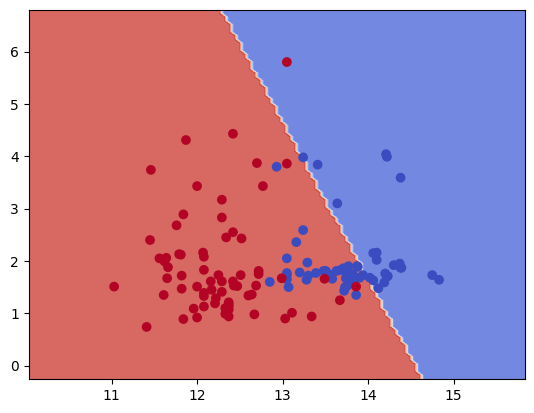

In [100]:
import numpy as np 
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn import datasets 
import matplotlib.pyplot as plt
X, y = datasets.load_wine().data[:128, :2], datasets.load_wine().target[:128]

lr = LogisticRegression()
lr.fit(X,y)

# set the coefficients

lr.coef_ = np.array([[-3,-1]])
# lr.intercept_ = np.array([-3])

DecisionBoundaryDisplay.from_estimator(
    lr,
    X,
    response_method="predict",
    cmap=plt.cm.coolwarm,
    alpha=0.8,
        # ax=ax,
        # xlabel=wine.feature_names[0],
        # ylabel=wine.feature_names[1],
)
plt.scatter(X[:,0], X[:,1], c = y, cmap=plt.cm.coolwarm)
lr.coef_

In [71]:
x,y, x*y, np.sum(x*y), x@y

(array([0, 1, 2]), array([3, 4, 5]), array([ 0,  4, 10]), 14, 14)